<a href="https://colab.research.google.com/github/LeaderTrusty/Raddauerzaehlstellen-Muenchen/blob/main/Fetch_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import requests
import pandas as pd

# 1. Query the Munich Open Data CKAN API
api_url = "https://opendata.muenchen.de/api/3/action/package_search"
params = {"q": "Raddauerzählstellen", "rows": 30}
response = requests.get(api_url, params=params).json()

# 2. Filter for 2022-2026 daily ("Tageswerte") CSV files
target_years = ["2022", "2023", "2024", "2025", "2026"]
csv_urls = []

for package in response["result"]["results"]:
    title = package.get("title", "")
    if any(year in title for year in target_years):
        for resource in package.get("resources", []):
            res_name = resource.get("name", "")
            res_format = resource.get("format", "").upper()
            if res_format == "CSV" and "tageswerte" in res_name.lower():
                csv_urls.append(resource["url"])

print(f"Found {len(csv_urls)} monthly daily-count CSV files.")

# 3. Download and combine all CSVs into one DataFrame
dfs = []
for url in csv_urls:
    try:
        df_temp = pd.read_csv(url)
        dfs.append(df_temp)
    except Exception as e:
        print(f"Skipped {url}: {e}")

master_df = pd.concat(dfs, ignore_index=True)

# 4. Save the combined dataset as a CSV in your Colab workspace
output_filename = "munich_bike_daily_2022_2026.csv"
master_df.to_csv(output_filename, index=False)
print(f"Saved {len(master_df):,} rows to '{output_filename}'")

Found 57 monthly daily-count CSV files.
Saved 8,408 rows to 'munich_bike_daily_2022_2026.csv'


In [17]:
import pandas as pd

df = pd.read_csv("munich_bike_daily_2022_2026.csv")

print("Shape (rows, columns):", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values per column:\n", df.isnull().sum())

df.head()

Shape (rows, columns): (8408, 16)

Columns: ['datum', 'uhrzeit_start', 'uhrzeit_ende', 'zaehlstelle', 'richtung_1', 'richtung_2', 'gesamt', 'min-temp', 'max-temp', 'niederschlag', 'bewoelkung', 'sonnenstunden', 'Unnamed: 0', 'min.temp', 'max.temp', 'datum     ']

Missing values per column:
 datum             124
uhrzeit_start       0
uhrzeit_ende        0
zaehlstelle         0
richtung_1         10
richtung_2         10
gesamt             10
min-temp          155
max-temp          155
niederschlag        0
bewoelkung          0
sonnenstunden       0
Unnamed: 0       8253
min.temp         8253
max.temp         8253
datum            8284
dtype: int64


,datum,uhrzeit_start,uhrzeit_ende,zaehlstelle,richtung_1,richtung_2,gesamt,min-temp,max-temp,niederschlag,bewoelkung,sonnenstunden,Unnamed: 0,min.temp,max.temp,datum
0,2025.01.01,00:00,23.59,Arnulf,235.0,19.0,254.0,-3.2,12.7,0.0,70,8.1,NaN,NaN,NaN,NaN
1,2025.01.02,00:00,23.59,Arnulf,370.0,38.0,408.0,0.3,10.5,15.7,95,0.0,NaN,NaN,NaN,NaN
2,2025.01.03,00:00,23.59,Arnulf,219.0,25.0,244.0,-3.3,0.9,0.0,49,5.1,NaN,NaN,NaN,NaN
3,2025.01.04,00:00,23.59,Arnulf,155.0,20.0,175.0,-5.4,0.2,12.5,65,6.1,NaN,NaN,NaN,NaN
4,2025.01.05,00:00,23.59,Arnulf,129.0,21.0,150.0,-2.0,9.8,11.4,96,0.0,NaN,NaN,NaN,NaN


In [4]:
from google.colab import files

files.download("munich_bike_daily_2022_2026.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import pandas as pd
import numpy as np

# 1. Load the raw master CSV
raw_df = pd.read_csv("munich_bike_daily_2022_2026.csv")

# 2. Standardize column names (lowercase and strip whitespace)
raw_df.columns = raw_df.columns.str.strip().str.lower()

# Coalesce duplicate columns by combining non-null values
unique_cols = list(dict.fromkeys(raw_df.columns))
clean_cols = {}
for col in unique_cols:
    cols_to_combine = raw_df.loc[:, raw_df.columns == col]
    if cols_to_combine.shape[1] > 1:
        clean_cols[col] = cols_to_combine.bfill(axis=1).iloc[:, 0]
    else:
        clean_cols[col] = cols_to_combine.iloc[:, 0]

df = pd.DataFrame(clean_cols)

# Rename to English
column_mapping = {
    "datum": "date",
    "uhrzeit_start": "start_time",
    "uhrzeit_ende": "end_time",
    "zaehlstelle": "station",
    "richtung_1": "direction_1",
    "richtung_2": "direction_2",
    "gesamt": "total_bikes",
    "min-temp": "min_temp_c",
    "max-temp": "max_temp_c",
    "min.temp": "min_temp_c",
    "max.temp": "max_temp_c",
    "niederschlag": "precipitation_mm",
    "bewoelkung": "cloud_cover_pct",
    "sonnenstunden": "sunshine_hours"
}
df = df.rename(columns=column_mapping)

# Since min_temp_c and max_temp_c can also have duplicate origins after renaming, we combine them if duplicates exist
df = df.groupby(level=0, axis=1).first()

# 3. Clean dates and remove any duplicate rows
df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce")
df = df.dropna(subset=["date", "station"])
df = df.drop_duplicates(subset=["date", "station"]).sort_values(["station", "date"]).reset_index(drop=True)

# 4. Ensure numeric columns are properly typed (handles accidental string/comma values)
numeric_cols = [
    "direction_1", "direction_2", "total_bikes",
    "min_temp_c", "max_temp_c", "precipitation_mm",
    "cloud_cover_pct", "sunshine_hours"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "."), errors="coerce")

# 5. Add useful calendar features for later analysis
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.day_name()
df["is_weekend"] = df["date"].dt.dayofweek >= 5

# 6. Detect sensor outages (0 bikes or missing total_bikes)
df["is_outage"] = df["total_bikes"].isna() | (df["total_bikes"] == 0)

# Print a Data Quality Audit summary
print("=== DATA QUALITY AUDIT ===")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Total rows: {len(df):,}")
print(f"Stations found ({df['station'].nunique()}): {df['station'].unique().tolist()}\n")

outage_summary = df.groupby("station").agg(
    total_days=("date", "count"),
    outage_days=("is_outage", "sum"),
    outage_pct=("is_outage", lambda x: round(x.mean() * 100, 2))
).sort_values("outage_days", ascending=False)

print("Sensor Outages by Station:")
display(outage_summary)

# 7. Save the cleaned dataset
clean_filename = "munich_bike_cleaned_2022_2026.csv"
df.to_csv(clean_filename, index=False)
print(f"\nSaved cleaned dataset to '{clean_filename}'")

/tmp/ipykernel_829/1426425754.py:42: FutureWarning: DataFrame.groupby with axis=1 is deprecated. Do `frame.T.groupby(...)` without axis instead.
  df = df.groupby(level=0, axis=1).first()


=== DATA QUALITY AUDIT ===
Date range: 2022-01-01 to 2026-09-30
Total rows: 8,284
Stations found (10): ['Arnulf', 'Erhardt', 'Erhardt    ', 'Hirsch', 'Hirsch     ', 'Kreuther', 'Kreuther   ', 'Margareten', 'Olympia', 'Olympia    ']

Sensor Outages by Station:


,total_days,outage_days,outage_pct
station,,,
Olympia,1683,74,4.40
Margareten,710,51,7.18
Kreuther,860,10,1.16
Arnulf,1622,0,0.00
Erhardt,1602,0,0.00
Erhardt,31,0,0.00
Hirsch,31,0,0.00
Hirsch,1683,0,0.00
Kreuther,31,0,0.00



Saved cleaned dataset to 'munich_bike_cleaned_2022_2026.csv'


In [20]:
df

,cloud_cover_pct,date,direction_1,direction_2,end_time,max_temp_c,min_temp_c,precipitation_mm,start_time,station,sunshine_hours,total_bikes,unnamed: 0,year,month,day_of_week,is_weekend,is_outage
0,68,2022-01-01,444.0,0.0,23.59,13.4,3.2,0.0,00:00,Arnulf,7.6,444.0,NaN,2022,1,Saturday,True,False
1,80,2022-01-02,476.0,0.0,23.59,15.8,1.9,0.0,00:00,Arnulf,4.7,476.0,NaN,2022,1,Sunday,True,False
2,99,2022-01-03,752.0,0.0,23.59,11.5,8.7,0.7,00:00,Arnulf,0.0,752.0,NaN,2022,1,Monday,False,False
3,98,2022-01-04,603.0,0.0,23.59,16.5,3.7,10.3,00:00,Arnulf,1.0,603.0,NaN,2022,1,Tuesday,False,False
4,95,2022-01-05,578.0,0.0,23.59,3.9,0.3,1.2,00:00,Arnulf,0.4,578.0,NaN,2022,1,Wednesday,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8279,89,2026-07-27,1325.0,1558.0,23:59,24.7,14.7,2.0,00:00,Olympia,3.5,2883.0,NaN,2026,7,Monday,False,False
8280,11,2026-07-28,1704.0,2251.0,23:59,29.7,14.3,0.0,00:00,Olympia,14.2,3955.0,NaN,2026,7,Tuesday,False,False
8281,10,2026-07-29,1982.0,1988.0,23:59,34.7,15.6,0.0,00:00,Olympia,13.8,3970.0,NaN,2026,7,Wednesday,False,False
8282,14,2026-07-30,2007.0,2043.0,23:59,37.1,22.2,0.0,00:00,Olympia,13.7,4050.0,NaN,2026,7,Thursday,False,False


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8408 entries, 0 to 8407
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              8284 non-null   object 
 1   start_time        8408 non-null   object 
 2   end_time          8408 non-null   object 
 3   station           8408 non-null   object 
 4   direction_1       8398 non-null   float64
 5   direction_2       8398 non-null   float64
 6   total_bikes       8398 non-null   float64
 7   min_temp_c        8253 non-null   float64
 8   max_temp_c        8253 non-null   float64
 9   precipitation_mm  8408 non-null   float64
 10  cloud_cover_pct   8408 non-null   int64  
 11  sunshine_hours    8408 non-null   float64
 12  unnamed: 0        155 non-null    float64
 13  min.temp          155 non-null    float64
 14  max.temp          155 non-null    float64
 15  date              124 non-null    object 
dtypes: float64(10), int64(1), object(5)
memory

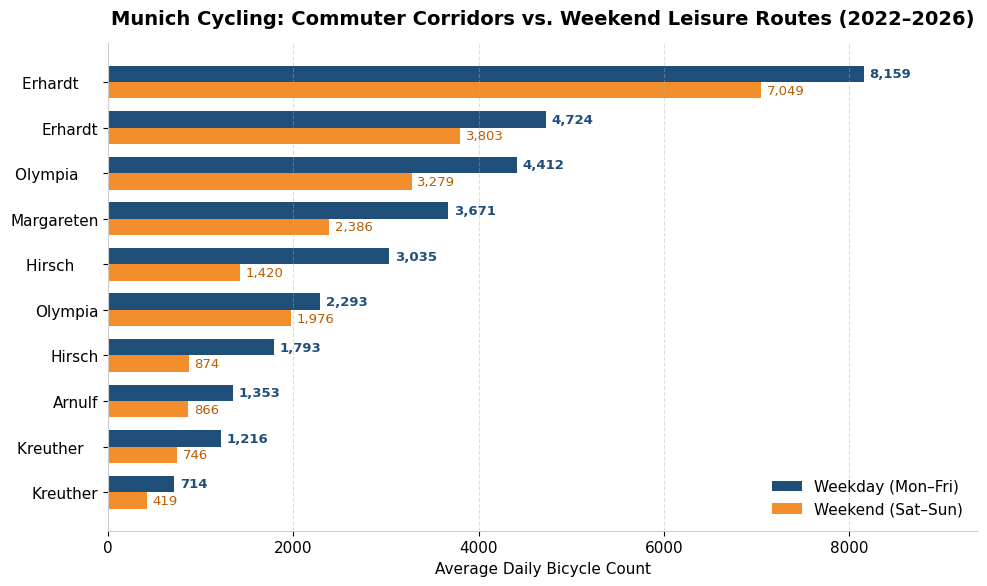

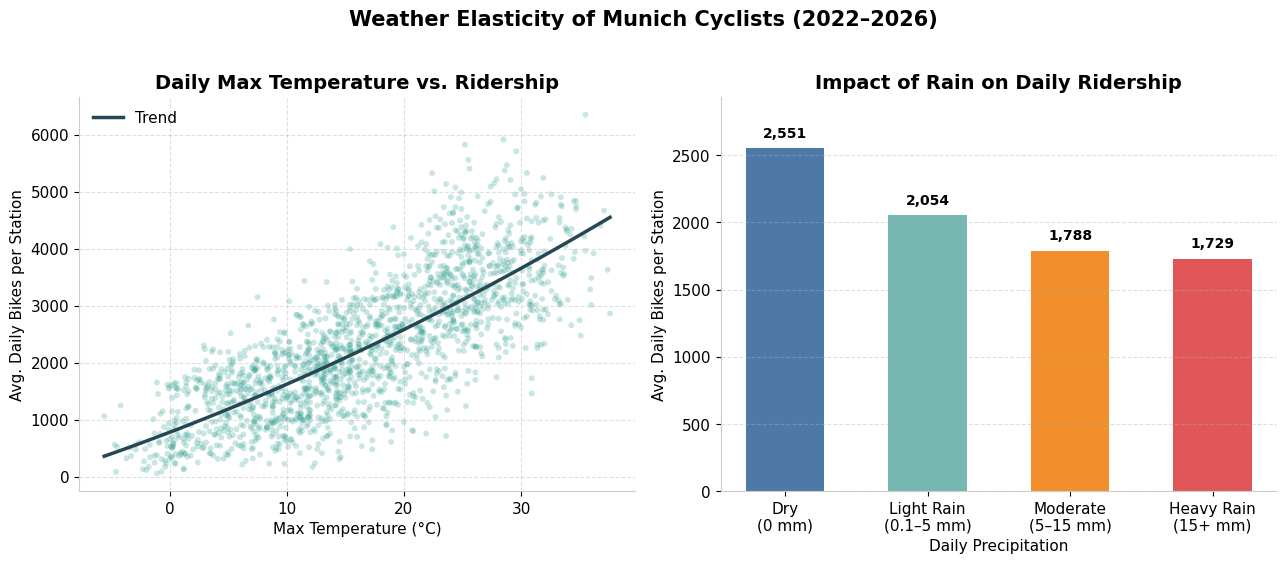

Charts saved as '01_commuter_vs_leisure.png' and '02_weather_impact.png'


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load cleaned data and exclude sensor outage days
df = pd.read_csv("munich_bike_cleaned_2022_2026.csv", parse_dates=["date"])
df_valid = df[~df["is_outage"]].copy()

# Set a clean, publication-ready visual style
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

# ==============================================================================
# CHART 1: Commuter vs. Leisure Patterns (Weekday vs. Weekend by Station)
# ==============================================================================
station_daytype = (
    df_valid.groupby(["station", "is_weekend"])["total_bikes"]
    .mean()
    .unstack()
    .rename(columns={False: "Weekday", True: "Weekend"})
    .sort_values("Weekday", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(station_daytype))
height = 0.36

bars_wd = ax.barh(y + height / 2, station_daytype["Weekday"], height, label="Weekday (Mon–Fri)", color="#1f4e79")
bars_we = ax.barh(y - height / 2, station_daytype["Weekend"], height, label="Weekend (Sat–Sun)", color="#f28e2b")

# Add value labels on bars
for bar in bars_wd:
    w = bar.get_width()
    ax.text(w + 60, bar.get_y() + bar.get_height() / 2, f"{w:,.0f}", va="center", fontsize=9.5, color="#1f4e79", fontweight="bold")

for bar in bars_we:
    w = bar.get_width()
    ax.text(w + 60, bar.get_y() + bar.get_height() / 2, f"{w:,.0f}", va="center", fontsize=9.5, color="#b85d00")

ax.set_yticks(y)
ax.set_yticklabels(station_daytype.index)
ax.set_xlabel("Average Daily Bicycle Count")
ax.set_title("Munich Cycling: Commuter Corridors vs. Weekend Leisure Routes (2022–2026)", pad=14)
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_xlim(0, station_daytype.max().max() * 1.15)

plt.tight_layout()
plt.savefig("01_commuter_vs_leisure.png", dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# CHART 2: Weather Impact (Temperature & Rain vs. Daily Cycling Volume)
# ==============================================================================
# Aggregate to daily mean per active station (avoids distortion if 1 station is offline)
daily_weather = (
    df_valid.groupby("date")
    .agg(
        avg_bikes_per_station=("total_bikes", "mean"),
        max_temp_c=("max_temp_c", "first"),
        precipitation_mm=("precipitation_mm", "first"),
    )
    .dropna()
)

# Bucket precipitation levels
bins = [-0.1, 0.0, 5.0, 15.0, float("inf")]
labels = ["Dry\n(0 mm)", "Light Rain\n(0.1–5 mm)", "Moderate\n(5–15 mm)", "Heavy Rain\n(15+ mm)"]
daily_weather["rain_category"] = pd.cut(daily_weather["precipitation_mm"], bins=bins, labels=labels)
rain_impact = daily_weather.groupby("rain_category", observed=False)["avg_bikes_per_station"].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# Panel A: Temperature vs. Cycling Volume
ax1.scatter(
    daily_weather["max_temp_c"],
    daily_weather["avg_bikes_per_station"],
    alpha=0.25,
    s=18,
    color="#2a9d8f",
    edgecolors="none",
)

# Add smooth polynomial trendline
z = np.polyfit(daily_weather["max_temp_c"], daily_weather["avg_bikes_per_station"], 2)
p = np.poly1d(z)
x_line = np.linspace(daily_weather["max_temp_c"].min(), daily_weather["max_temp_c"].max(), 100)
ax1.plot(x_line, p(x_line), color="#264653", linewidth=2.5, label="Trend")

ax1.set_title("Daily Max Temperature vs. Ridership")
ax1.set_xlabel("Max Temperature (°C)")
ax1.set_ylabel("Avg. Daily Bikes per Station")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(linestyle="--", alpha=0.4)
ax1.legend(frameon=False, loc="upper left")

# Panel B: Precipitation Impact
colors = ["#4e79a7", "#76b7b2", "#f28e2b", "#e15759"]
bars = ax2.bar(rain_impact.index, rain_impact.values, color=colors, width=0.55)

for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 60, f"{h:,.0f}", ha="center", va="bottom", fontweight="bold", fontsize=10)

ax2.set_title("Impact of Rain on Daily Ridership")
ax2.set_xlabel("Daily Precipitation")
ax2.set_ylabel("Avg. Daily Bikes per Station")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.set_ylim(0, rain_impact.max() * 1.15)

fig.suptitle("Weather Elasticity of Munich Cyclists (2022–2026)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("02_weather_impact.png", dpi=300, bbox_inches="tight")
plt.show()

print("Charts saved as '01_commuter_vs_leisure.png' and '02_weather_impact.png'")